In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import KFold, train_test_split




In [9]:
DATA_URL = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

DATA_FILE = Path("course_lead_scoring_2026.csv")
TARGET = "converted"

if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE)
else:
    df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [10]:
feature_df = df.drop(columns=[TARGET])

categorical = (
    feature_df
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

numerical = (
    feature_df
    .select_dtypes(exclude=["object", "category"])
    .columns
    .tolist()
)

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1,
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[TARGET].values
y_val = df_val[TARGET].values

X_train_df = df_train.drop(columns=[TARGET])
X_val_df = df_val.drop(columns=[TARGET])

print("Train:", X_train_df.shape)
print("Validation:", X_val_df.shape)
print("Test:", df_test.shape)


Train: (3000, 8)
Validation: (1000, 8)
Test: (1000, 9)


/tmp/ipykernel_4289/2680682620.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=["object", "category"])


In [11]:
auc_scores = {}

for feature in numerical:
    auc = roc_auc_score(y_train, X_train_df[feature])

    if auc < 0.5:
        auc = 1 - auc

    auc_scores[feature] = auc

q1_candidates = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]

for feature in q1_candidates:
    print(f"{feature:30s}: {auc_scores[feature]:.6f}")

q1_answer = max(q1_candidates, key=auc_scores.get)
print("\nQ1 ANSWER:", q1_answer)


lead_score                    : 0.788225
number_of_courses_viewed      : 0.722989
interaction_count             : 0.764920
annual_income                 : 0.608198

Q1 ANSWER: lead_score


In [12]:
def train_model(df_train, y_train, df_val, c=1.0):
    dv = DictVectorizer(sparse=False)

    train_dicts = df_train.to_dict(orient="records")
    val_dicts = df_val.to_dict(orient="records")

    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(
        solver="liblinear",
        C=c,
        max_iter=1000,
    )

    model.fit(X_train, y_train)

    return model, dv, X_val


In [13]:
model, dv, X_val = train_model(
    X_train_df,
    y_train,
    X_val_df,
    c=1.0,
)

y_pred = model.predict_proba(X_val)[:, 1]
q2_answer = roc_auc_score(y_val, y_pred)

print(f"Q2 ANSWER: {q2_answer:.3f}")


Q2 ANSWER: 0.732


In [14]:
thresholds = np.arange(0.0, 1.0, 0.01)

precisions = []
recalls = []
f1_scores = []
intersection_candidates = []

for threshold in thresholds:
    predictions = (y_pred >= threshold).astype(int)

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0,
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0,
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0,
    )

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)

    if not (precision == 0 and recall == 0):
        intersection_candidates.append(
            (abs(precision - recall), threshold)
        )

_, q3_answer = min(intersection_candidates)

best_f1_index = int(np.argmax(f1_scores))
q4_answer = thresholds[best_f1_index]

print(f"Q3 ANSWER: {q3_answer:.2f}")
print(f"Q4 ANSWER: {q4_answer:.2f}")
print(f"Maximum F1: {f1_scores[best_f1_index]:.6f}")


Q3 ANSWER: 0.63
Q4 ANSWER: 0.41
Maximum F1: 0.757616


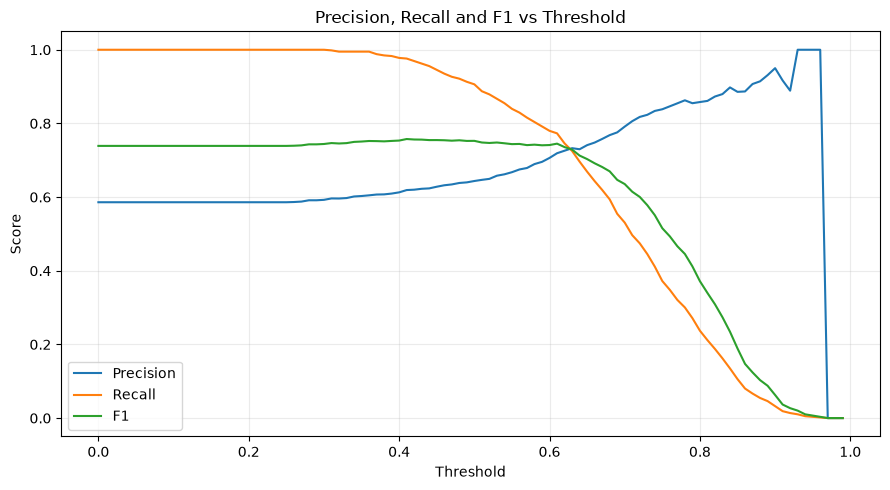

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.plot(thresholds, f1_scores, label="F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [16]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1,
)

cv_scores = []

for fold_number, (train_idx, val_idx) in enumerate(
    kfold.split(df_full_train),
    start=1,
):
    fold_train = df_full_train.iloc[train_idx].copy()
    fold_val = df_full_train.iloc[val_idx].copy()

    fold_y_train = fold_train[TARGET].values
    fold_y_val = fold_val[TARGET].values

    fold_X_train = fold_train.drop(columns=[TARGET])
    fold_X_val = fold_val.drop(columns=[TARGET])

    fold_model, _, fold_X_val_encoded = train_model(
        fold_X_train,
        fold_y_train,
        fold_X_val,
        c=1.0,
    )

    fold_pred = fold_model.predict_proba(
        fold_X_val_encoded
    )[:, 1]

    fold_auc = roc_auc_score(
        fold_y_val,
        fold_pred,
    )

    cv_scores.append(fold_auc)
    print(f"Fold {fold_number}: {fold_auc:.6f}")

q5_answer = np.std(cv_scores)

print(f"\nMean AUC: {np.mean(cv_scores):.6f}")
print(f"Q5 ANSWER: {q5_answer:.3f}")


Fold 1: 0.730560
Fold 2: 0.729573
Fold 3: 0.736343
Fold 4: 0.741245
Fold 5: 0.720914

Mean AUC: 0.731727
Q5 ANSWER: 0.007


In [17]:
c_values = [0.000001, 0.001, 1]
results = {}

for c in c_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx].copy()
        fold_val = df_full_train.iloc[val_idx].copy()

        fold_y_train = fold_train[TARGET].values
        fold_y_val = fold_val[TARGET].values

        fold_X_train = fold_train.drop(columns=[TARGET])
        fold_X_val = fold_val.drop(columns=[TARGET])

        fold_model, _, fold_X_val_encoded = train_model(
            fold_X_train,
            fold_y_train,
            fold_X_val,
            c=c,
        )

        fold_pred = fold_model.predict_proba(
            fold_X_val_encoded
        )[:, 1]

        fold_auc = roc_auc_score(
            fold_y_val,
            fold_pred,
        )

        scores.append(fold_auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results[c] = (mean_auc, std_auc)

    print(
        f"C={c:g} | "
        f"mean={mean_auc:.3f} | "
        f"std={std_auc:.3f}"
    )

q6_answer = max(
    results,
    key=lambda c: (
        round(results[c][0], 3),
        -round(results[c][1], 3),
        -c,
    ),
)

print(f"\nQ6 ANSWER: {q6_answer:g}")


C=1e-06 | mean=0.617 | std=0.019
C=0.001 | mean=0.749 | std=0.010
C=1 | mean=0.732 | std=0.007

Q6 ANSWER: 0.001
